In [77]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [78]:
from google.colab import drive, output

drive.mount("/content/AMBA_project")

Drive already mounted at /content/AMBA_project; to attempt to forcibly remount, call drive.mount("/content/AMBA_project", force_remount=True).


In [79]:
train=pd.read_csv("/content/AMBA_project/MyDrive/AMBA/AMBA_project/train_v9rqX0R.csv")
test=pd.read_csv("/content/AMBA_project/MyDrive/AMBA/AMBA_project/test_AbJTz2l.csv")

print("Train dataset details\n")
print("Shape:",train.shape)
display(train.head())
print("Data info:\n",train.info())

print("\nTest dataset details\n")
print("Shape:",test.shape)
display(test.head())

Train dataset details

Shape: (8523, 12)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB
Data info:
 None

Test dataset details

Shape

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type
0,FDW58,20.750,Low Fat,0.007565,Snack Foods,107.8622,OUT049,1999,Medium,Tier 1,Supermarket Type1
1,FDW14,8.300,reg,0.038428,Dairy,87.3198,OUT017,2007,NaN,Tier 2,Supermarket Type1
2,NCN55,14.600,Low Fat,0.099575,Others,241.7538,OUT010,1998,NaN,Tier 3,Grocery Store
3,FDQ58,7.315,Low Fat,0.015388,Snack Foods,155.0340,OUT017,2007,NaN,Tier 2,Supermarket Type1
4,FDY38,NaN,Regular,0.118599,Dairy,234.2300,OUT027,1985,Medium,Tier 3,Supermarket Type3


In [80]:
target="Item_Outlet_Sales"

(Item_identifier,outlet_identifier) will be used to uniquely identify a row

In [81]:
# Are the same stores and products present in both files?
print('\nOutlets\ntrain:', train['Outlet_Identifier'].nunique(),'\ntest:', test['Outlet_Identifier'].nunique(),
      '\ntest outlets unseen in train:',
      len(set(test['Outlet_Identifier']) - set(train['Outlet_Identifier'])))
print('\nItems\ntrain:', train['Item_Identifier'].nunique(),
      '\ntest:', test['Item_Identifier'].nunique(),
      '\ntest items unseen in train:',
      len(set(test['Item_Identifier']) - set(train['Item_Identifier'])))

# Duplicate rows / duplicate item-outlet pairs
print('\nDuplicate item-outlet pairs in train:',
      train.duplicated(['Item_Identifier', 'Outlet_Identifier']).sum())


Outlets
train: 10 
test: 10 
test outlets unseen in train: 0

Items
train: 1559 
test: 1543 
test items unseen in train: 0

Duplicate item-outlet pairs in train: 0


both train and test have all the same stores and products so model can learn directly

In [82]:
#check number of missing values in each columns and overall dataset
print("Missing values in train:")
for i in range(len(train.columns)):
  print(train.columns[i],":",train.iloc[:,i].isna().sum())
print("Total missing values:",train.isna().sum().sum())

print("\nMissing value in test:")
for i in range(len(test.columns)):
  print(train.columns[i],":",test.iloc[:,i].isna().sum())
print("Total missing values:",test.isna().sum().sum())

Missing values in train:
Item_Identifier : 0
Item_Weight : 1463
Item_Fat_Content : 0
Item_Visibility : 0
Item_Type : 0
Item_MRP : 0
Outlet_Identifier : 0
Outlet_Establishment_Year : 0
Outlet_Size : 2410
Outlet_Location_Type : 0
Outlet_Type : 0
Item_Outlet_Sales : 0
Total missing values: 3873

Missing value in test:
Item_Identifier : 0
Item_Weight : 976
Item_Fat_Content : 0
Item_Visibility : 0
Item_Type : 0
Item_MRP : 0
Outlet_Identifier : 0
Outlet_Establishment_Year : 0
Outlet_Size : 1606
Outlet_Location_Type : 0
Outlet_Type : 0
Total missing values: 2582


missing values is only present in Item_weight and Outlet_Size for both train and test

# EDA


## Univariate analysis
1. Numeric columns (Item_Weight, Item_Visibility, Item_MRP)
2. Categorical columns (Item_Fat_Content, Item_Type, Outlet_Identifier, Outlet_Size, Outlet_Location_Type, Outlet_Type)

<IPython.core.display.Javascript object>

,Item_Weight,Item_Visibility,Item_MRP
count,7060.000000,8523.000000,8523.000000
mean,12.857645,0.066132,140.992782
std,4.643456,0.051598,62.275067
min,4.555000,0.000000,31.290000
25%,8.773750,0.026989,93.826500
50%,12.600000,0.053931,143.012800
75%,16.850000,0.094585,185.643700
max,21.350000,0.328391,266.888400


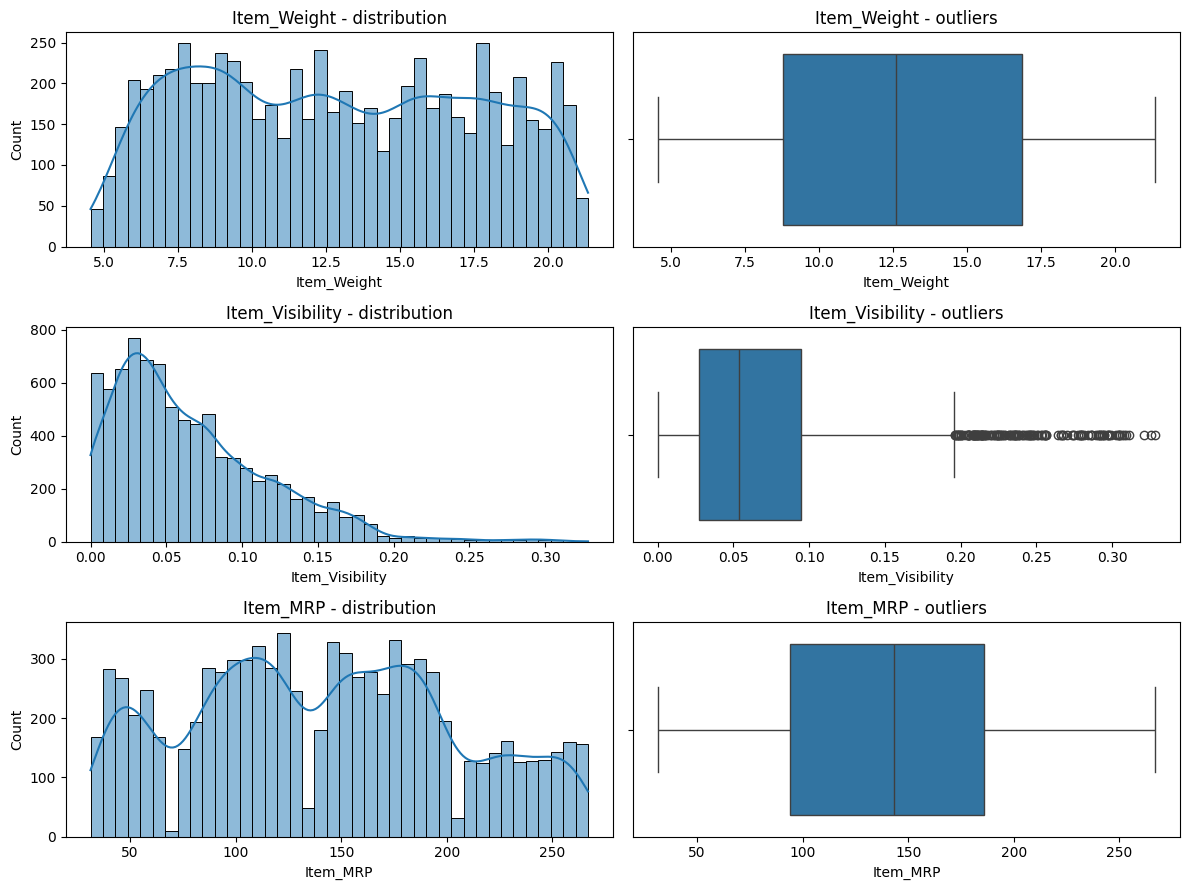

In [83]:
output.no_vertical_scroll()
num_cols = ['Item_Weight', 'Item_Visibility', 'Item_MRP']

#statistics
summary = train[num_cols].describe()
display(summary)

# Histogram and box plot for each column
fig, axes = plt.subplots(len(num_cols), 2, figsize=(12, 3 * len(num_cols)))
for i, col in enumerate(num_cols):
    sns.histplot(train[col].dropna(), bins=40, kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f'{col} - distribution')
    sns.boxplot(x=train[col], ax=axes[i, 1])
    axes[i, 1].set_title(f'{col} - outliers')
plt.tight_layout()
plt.show()

Raw (non-zero)   skew: 1.231
log              skew: -0.425


/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


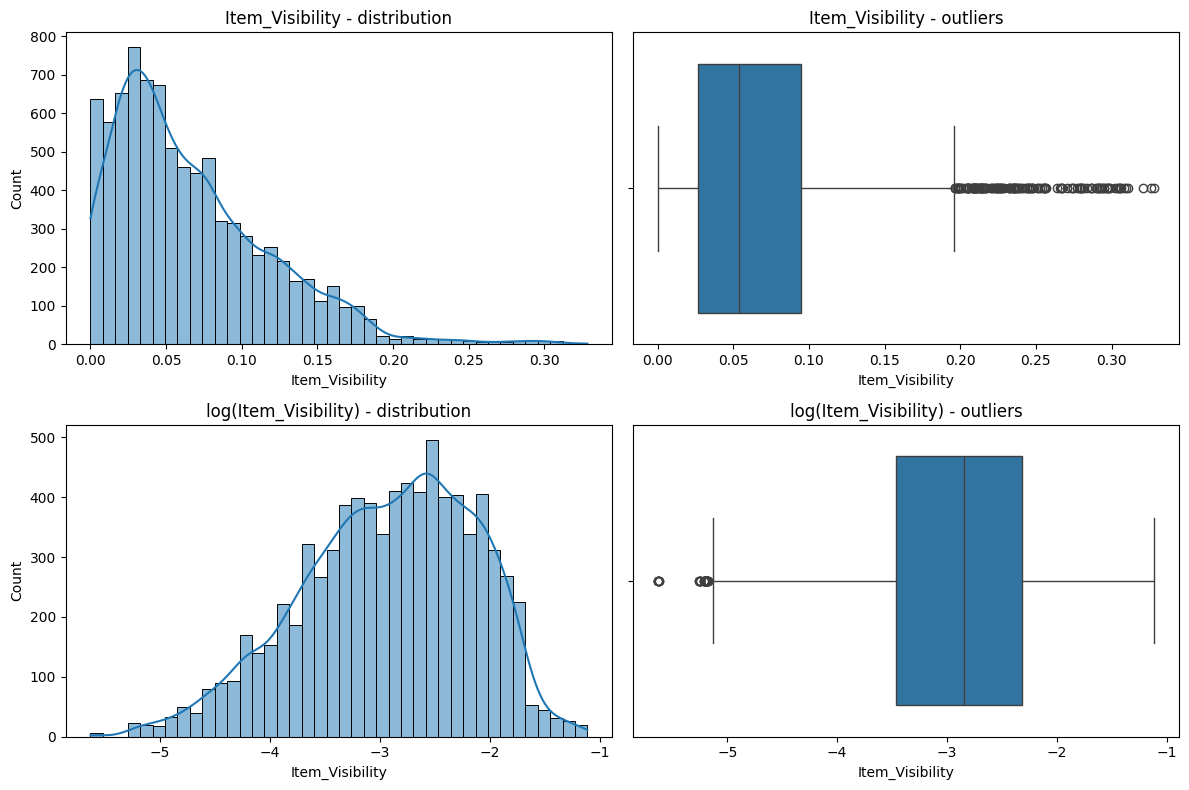

In [84]:
#Taking log in Item_Visibility to fix skewness

v = train['Item_Visibility']
nz = v[v > 0]                                    # exclude disguised-missing zeros
print('Raw (non-zero)   skew:', round(nz.skew(), 3))
print('log              skew:', round(np.log(nz).skew(), 3))

#plotting the histplot for raw, log1p, log and sqrt and boxplot
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(v, bins=40, kde=True, ax=axes[0, 0])
axes[0, 0].set_title(f'Item_Visibility - distribution')
sns.boxplot(x=v, ax=axes[0, 1])
axes[0, 1].set_title(f'Item_Visibility - outliers')

sns.histplot(np.log(v), bins=40, kde=True, ax=axes[1, 0])
axes[1, 0].set_title(f'log(Item_Visibility) - distribution')
sns.boxplot(x=np.log(v), ax=axes[1, 1])
axes[1, 1].set_title(f'log(Item_Visibility) - outliers')

plt.tight_layout()
plt.show()

In [85]:
#outlier count on log(Item_Visibility) by IQR rule, 3 sigma rule and 99 percentile rule
col = np.log(train['Item_Visibility'].replace(0, np.nan)) # Exclude 0 to avoid -inf values
q1, q3 = col.quantile([0.25, 0.75])
iqr = q3 - q1
n_out = ((col < q1 - 1.5 * iqr) | (col > q3 + 1.5 * iqr)).sum()
print(f'{n_out} outliers (IQR rule)')

col_mean=col.mean()
col_std=col.std()
upper_limit=col_mean+3*col_std
lower_limit=col_mean-3*col_std
n_out=((col<lower_limit)|(col>upper_limit)).sum()
print(f'{n_out} outliers (3 sigma rule)')

p99=col.quantile(0.99)
n_out_p99 = (col > p99).sum()
print(f'{n_out_p99} outliers (99 percentile rule)')

32 outliers (IQR rule)
6 outliers (3 sigma rule)
80 outliers (99 percentile rule)


taking log on Item_Visibility is confusing as IQR rule outlier and 3 sigma rule outlier gets reduced compared to Item_Visibility but percentile rule does not reduce that much, also Item_Visibility is already in decimal(percentage value) so taking log gives values in negative

In [86]:
# Outlier count using the IQR rule, 3 sigma rule and 99 percentile rule
for col in num_cols:
    print(f'\n{col}')
    q1, q3 = train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((train[col] < q1 - 1.5 * iqr) | (train[col] > q3 + 1.5 * iqr)).sum()
    print(f'{n_out} outliers (IQR rule)')

    col_mean=train[col].mean()
    col_std=train[col].std()
    upper_limit=col_mean+3*col_std
    lower_limit=col_mean-3*col_std
    n_out=((train[col]<lower_limit)|(train[col]>upper_limit)).sum()
    print(f'{n_out} outliers (3 sigma rule)')

    p99=train[col].quantile(0.99)
    n_out_p99 = (train[col] > p99).sum()
    print(f'{n_out_p99} outliers (99 percentile rule)')


Item_Weight
0 outliers (IQR rule)
0 outliers (3 sigma rule)
59 outliers (99 percentile rule)

Item_Visibility
144 outliers (IQR rule)
95 outliers (3 sigma rule)
86 outliers (99 percentile rule)

Item_MRP
0 outliers (IQR rule)
0 outliers (3 sigma rule)
85 outliers (99 percentile rule)


checking if Item_Visibility==0 means anythings, like a side gift or discounted product on purchase with other products, or if it is missing values indisguise

In [87]:
z = train['Item_Visibility'] == 0
display(train.groupby(z)[target].describe())

,count,mean,std,min,25%,50%,75%,max
Item_Visibility,,,,,,,,
False,7997.0,2178.575445,1704.227930,33.29,829.58680,1794.3310,3098.6332,13086.9648
True,526.0,2222.542928,1741.803049,33.29,891.33975,1774.0241,3182.5240,11445.1020


the mean and median sales are nearly same for Visibility 0 and non 0 items, so i conclude Item_Visibility==0 as missing values

Or maybe Item_Visibility has no or very less impact on sales

2. Categorical columns (Item_Fat_Content, Item_Type, Outlet_Identifier, Outlet_Size, Outlet_Location_Type, Outlet_Type)

<IPython.core.display.Javascript object>

Unique Item_Identifier values: 1559

Item_Fat_Content


,count,percent
Item_Fat_Content,,
Low Fat,5089,59.7
Regular,2889,33.9
LF,316,3.7
reg,117,1.4
low fat,112,1.3



Item_Type


,count,percent
Item_Type,,
Fruits and Vegetables,1232,14.5
Snack Foods,1200,14.1
Household,910,10.7
Frozen Foods,856,10.0
Dairy,682,8.0
Canned,649,7.6
Baking Goods,648,7.6
Health and Hygiene,520,6.1
Soft Drinks,445,5.2


...

,count,percent
Outlet_Size,,
Medium,2793,32.8
NaN,2410,28.3
Small,2388,28.0
High,932,10.9



Outlet_Location_Type


,count,percent
Outlet_Location_Type,,
Tier 3,3350,39.3
Tier 2,2785,32.7
Tier 1,2388,28.0



Outlet_Type


,count,percent
Outlet_Type,,
Supermarket Type1,5577,65.4
Grocery Store,1083,12.7
Supermarket Type3,935,11.0
Supermarket Type2,928,10.9


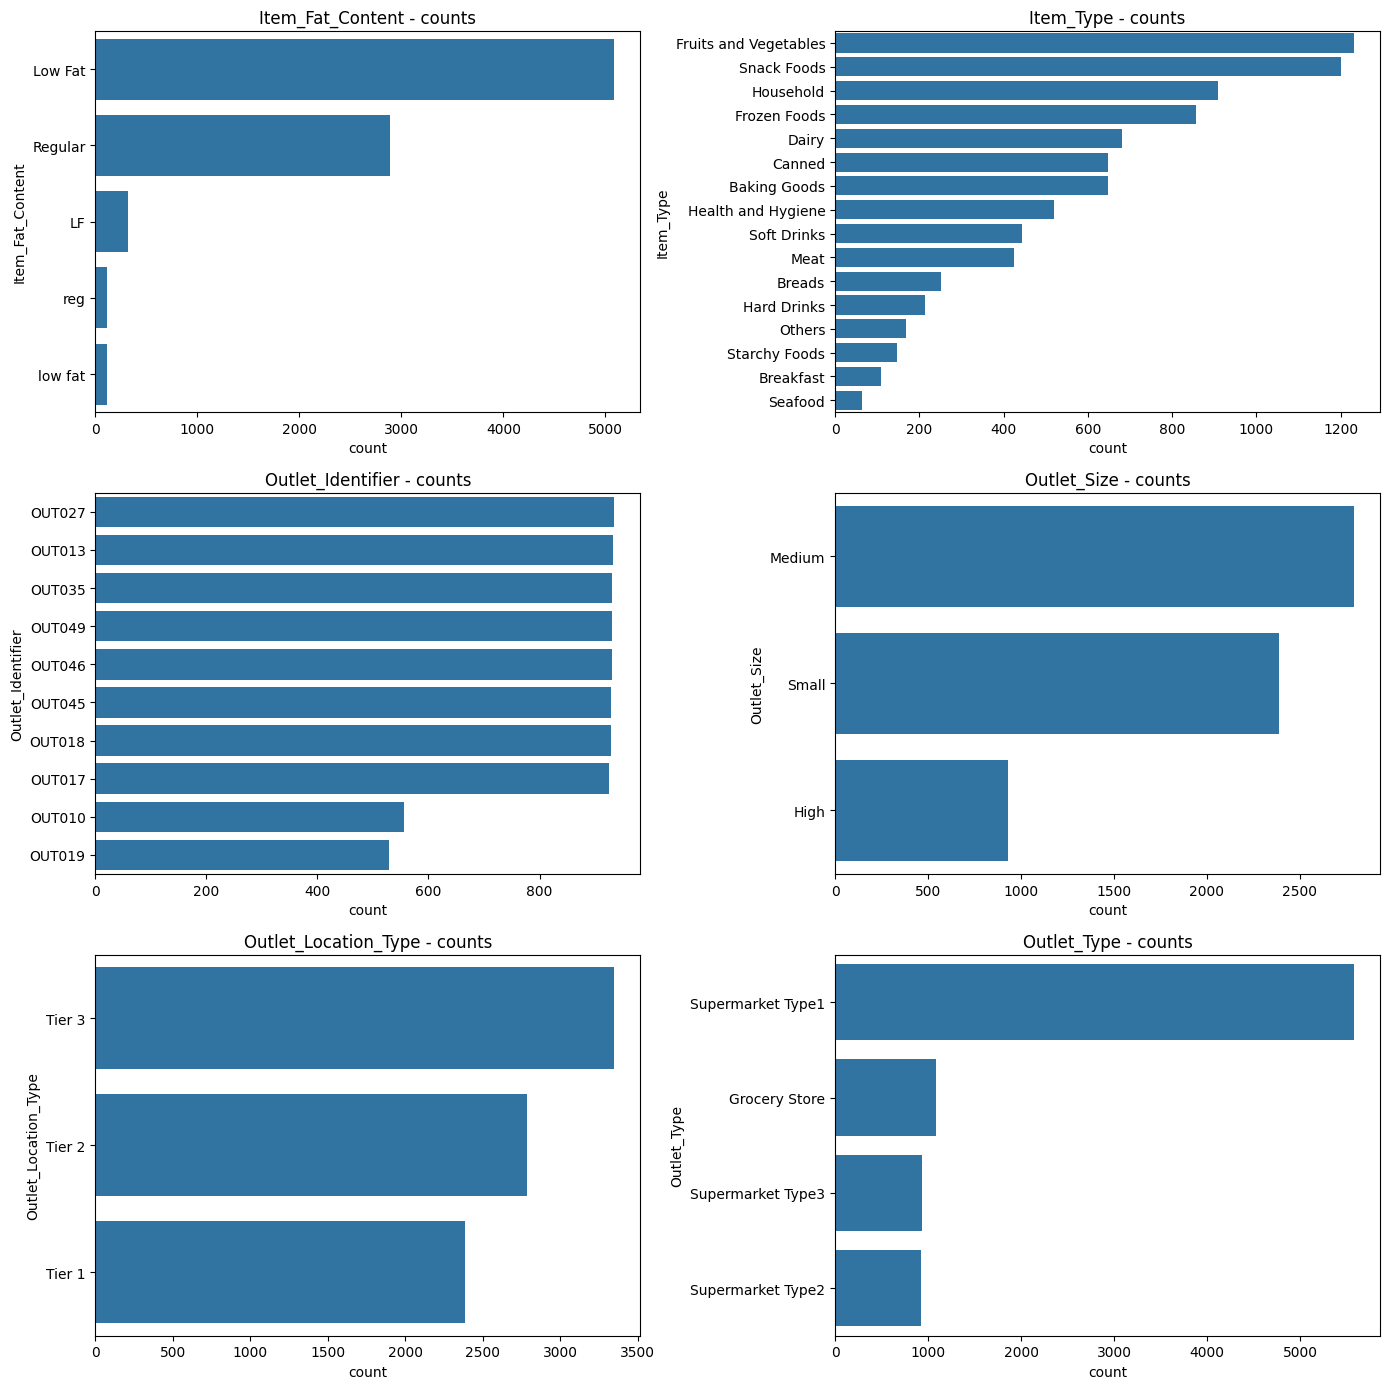

In [88]:
output.no_vertical_scroll()
cat_cols = ['Item_Fat_Content', 'Item_Type', 'Outlet_Identifier',
            'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type']

print('Unique Item_Identifier values:', train['Item_Identifier'].nunique())

for col in cat_cols:
    print(f'\n{col}')
    counts = train[col].value_counts(dropna=False)
    display(pd.DataFrame({'count': counts,
                          'percent': (counts / len(train) * 100).round(1)}))

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
for ax, col in zip(axes.flat, cat_cols):
    order = train[col].value_counts().index
    sns.countplot(data=train, y=col, order=order, ax=ax)
    ax.set_title(f'{col} - counts')
plt.tight_layout()
plt.show()

The missing counts matched specific store row counts exactly. Outlet_Size was missing only for OUT010, OUT017 and OUT045, and Item_Weight only for OUT019 and OUT027. This shows the gaps are store-level reporting failures, not random.

# Section A conclusions

##Numeric columns

1. Item_Weight is evenly spread (4.6–21.4) with no outliers, but has 1463 missing values. Those match the row counts of OUT019 and OUT027 exactly, so the gaps look like a store-level reporting failure.
2. Item_Visibility is right-skewed (skew 1.23).
Its 526 zeros are disguised missing values: their sales match normal items, so the “free gift” hypothesis was rejected.
Its high values look genuine.
sqrt reduces the skew best (0.41). We’ll use it only for linear regression, after filling the zeros, and won’t create a log version.
3. Item_MRP is clean, with no outliers, and falls into four distinct price clusters. That’s a candidate for an MRP_Band feature.
4. Outlet_Establishment_Year has only about 9 distinct values. It’s a store attribute rather than a true continuous variable, so we’ll convert it to outlet age (2013 − year).
5. Item_Outlet_Sales (the target) is right-skewed (skew 1.18), with the mean (2181) above the median (1794). It has 186 IQR outliers, which are real best-sellers.

##Outliers

1. The outliers in visibility and sales are genuine, so we keep them all, with no removal or capping. IQR is the right detection rule for these skewed columns. The 99th-percentile rule isn’t an outlier test; it always flags about 1% of values.

## Categorical columns

1. Item_Fat_Content has 5 inconsistent labels that collapse into 2 (Low Fat and Regular). Non-food items also appear to carry fat labels; we’ll verify this in Section B.
2. Item_Type has 16 imbalanced categories, with rare ones such as Seafood and Breakfast. The item ID prefix (FD/DR/NC) offers a cleaner 3-group Item_Category.
3. Outlets: two stores (OUT010 and OUT019) have about 40% fewer rows, and together they make up exactly the Grocery Store rows. So grocery stores stock fewer products.
4. Outlet_Size has 2410 missing values, which match OUT010, OUT017 and OUT045 exactly. Three stores never reported their size.
5. Outlet_Type is nearly the same as the store: Type2 and Type3 are one store each. So the store attributes are largely redundant with Outlet_Identifier. We’ll quantify this in the multicollinearity check.

## Bivariate analysis (each feature against sales)
1. Numeric vs sales: a scatter plot of each numeric feature against sales, plus a correlation heatmap. This shows which numeric features relate to sales (we expect MRP to be strong).
2. Categorical vs sales: box plots or mean-sales bar charts for each category column (for example sales by Outlet_Type, by store and by Item_Type). This shows which groups sell more.
3. Multicollinearity (relationships between the features themselves):
* Correlation heatmap of the numeric features (Pearson), to find highly correlated pairs (|r| > 0.7).
* VIF (Variance Inflation Factor) for the numeric features. VIF measures how well one feature can be predicted from the others. As a rule of thumb, VIF > 5 is a concern and VIF > 10 is serious. Rows with missing values will be skipped for now.
* Cramér’s V for pairs of categorical columns (the categorical version of correlation, from 0 to 1). I expect the store attributes (Outlet_Size, Outlet_Type, Outlet_Location_Type, establishment year) to be almost fully determined by Outlet_Identifier, because each store has a single fixed value for each of them.

<IPython.core.display.Javascript object>

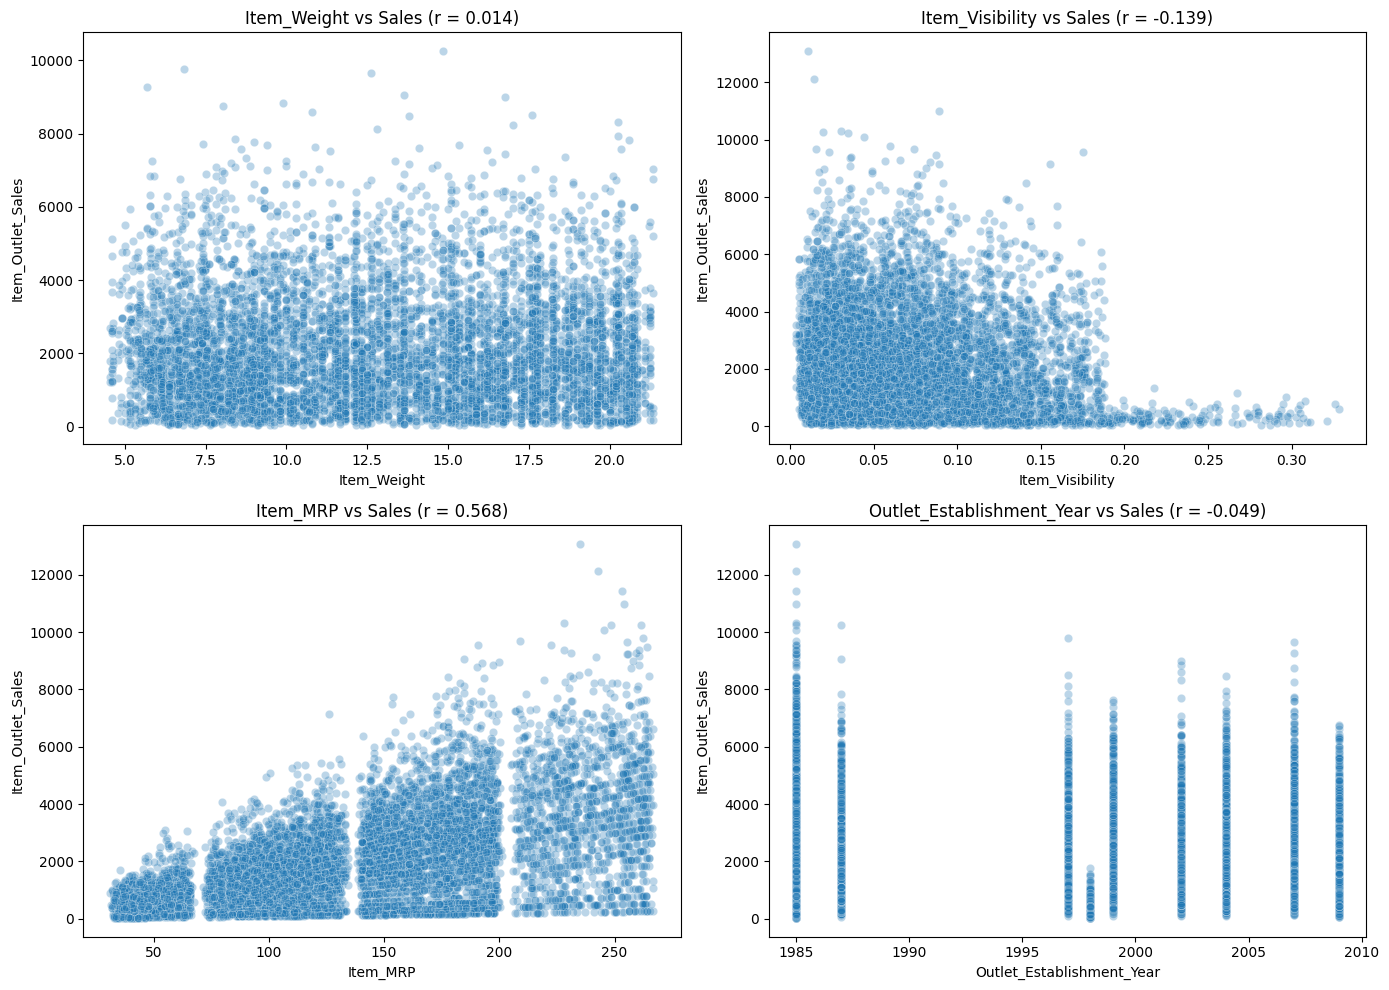

,pearson,spearman
Item_MRP,0.568,0.563
Item_Weight,0.014,0.015
Outlet_Establishment_Year,-0.049,0.043
Item_Visibility,-0.129,-0.115


In [89]:
output.no_vertical_scroll()
#numeric features v/s sales
num_feats = ['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Outlet_Establishment_Year']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.flat, num_feats):
    d = train[[col, target]].dropna()
    if col == 'Item_Visibility':
        d = d[d[col] > 0]                      # exclude disguised-missing zeros
    sns.scatterplot(data=d, x=col, y=target, alpha=0.3, ax=ax)
    ax.set_title(f'{col} vs Sales (r = {d[col].corr(d[target]):.3f})')
plt.tight_layout()
plt.show()

corr = pd.DataFrame({
    'pearson':  train[num_feats].corrwith(train[target]),
    'spearman': train[num_feats].corrwith(train[target], method='spearman')
}).sort_values('pearson', ascending=False)
display(corr.round(3))

##Numeric features vs sales

1. Item_MRP is the strongest predictor (r = 0.57, with Pearson and Spearman almost equal, so the relationship is close to linear). Sales spread out more as price rises (a fan shape), so errors will be larger for expensive items. The 4 price bands are visible.
2. Item_Weight has no relationship with sales (r = 0.01). It’s expected to be a weak predictor.
3. Item_Visibility has a weak negative correlation (r = −0.14), but it’s confounded by store type. Grocery stores display each item more (visibility 0.111 vs 0.065) and also sell far less, which creates a misleading negative link.
4. Establishment_Year behaves like a store label, not a trend (r = −0.05). Each year corresponds to specific stores: 1998 is a grocery store, and 1985 mixes the top seller with a grocery store.

<IPython.core.display.Javascript object>

Eta squared (strength of each categorical feature vs sales):


,0
Outlet_Identifier,0.241
Outlet_Type,0.240
Outlet_Size,0.048
Outlet_Location_Type,0.013
Item_Type,0.005
Item_Fat_Content,0.000



Item_Fat_Content


,count,mean,median
Item_Fat_Content,,,
Regular,3006,2224.6,1844.6
Low Fat,5517,2157.7,1765.0


...

,count,mean,median
Outlet_Size,,,
Medium,2793,2681.6,2251.1
High,932,2299.0,2050.7
Small,2388,1912.1,1544.7
Missing,2410,1822.6,1443.5



Outlet_Location_Type


,count,mean,median
Outlet_Location_Type,,,
Tier 2,2785,2324.0,2004.1
Tier 3,3350,2279.6,1812.3
Tier 1,2388,1876.9,1487.4



Outlet_Type


,count,mean,median
Outlet_Type,,,
Supermarket Type3,935,3694.0,3365.0
Supermarket Type1,5577,2316.2,1990.7
Supermarket Type2,928,1995.5,1655.2
Grocery Store,1083,339.8,257.0


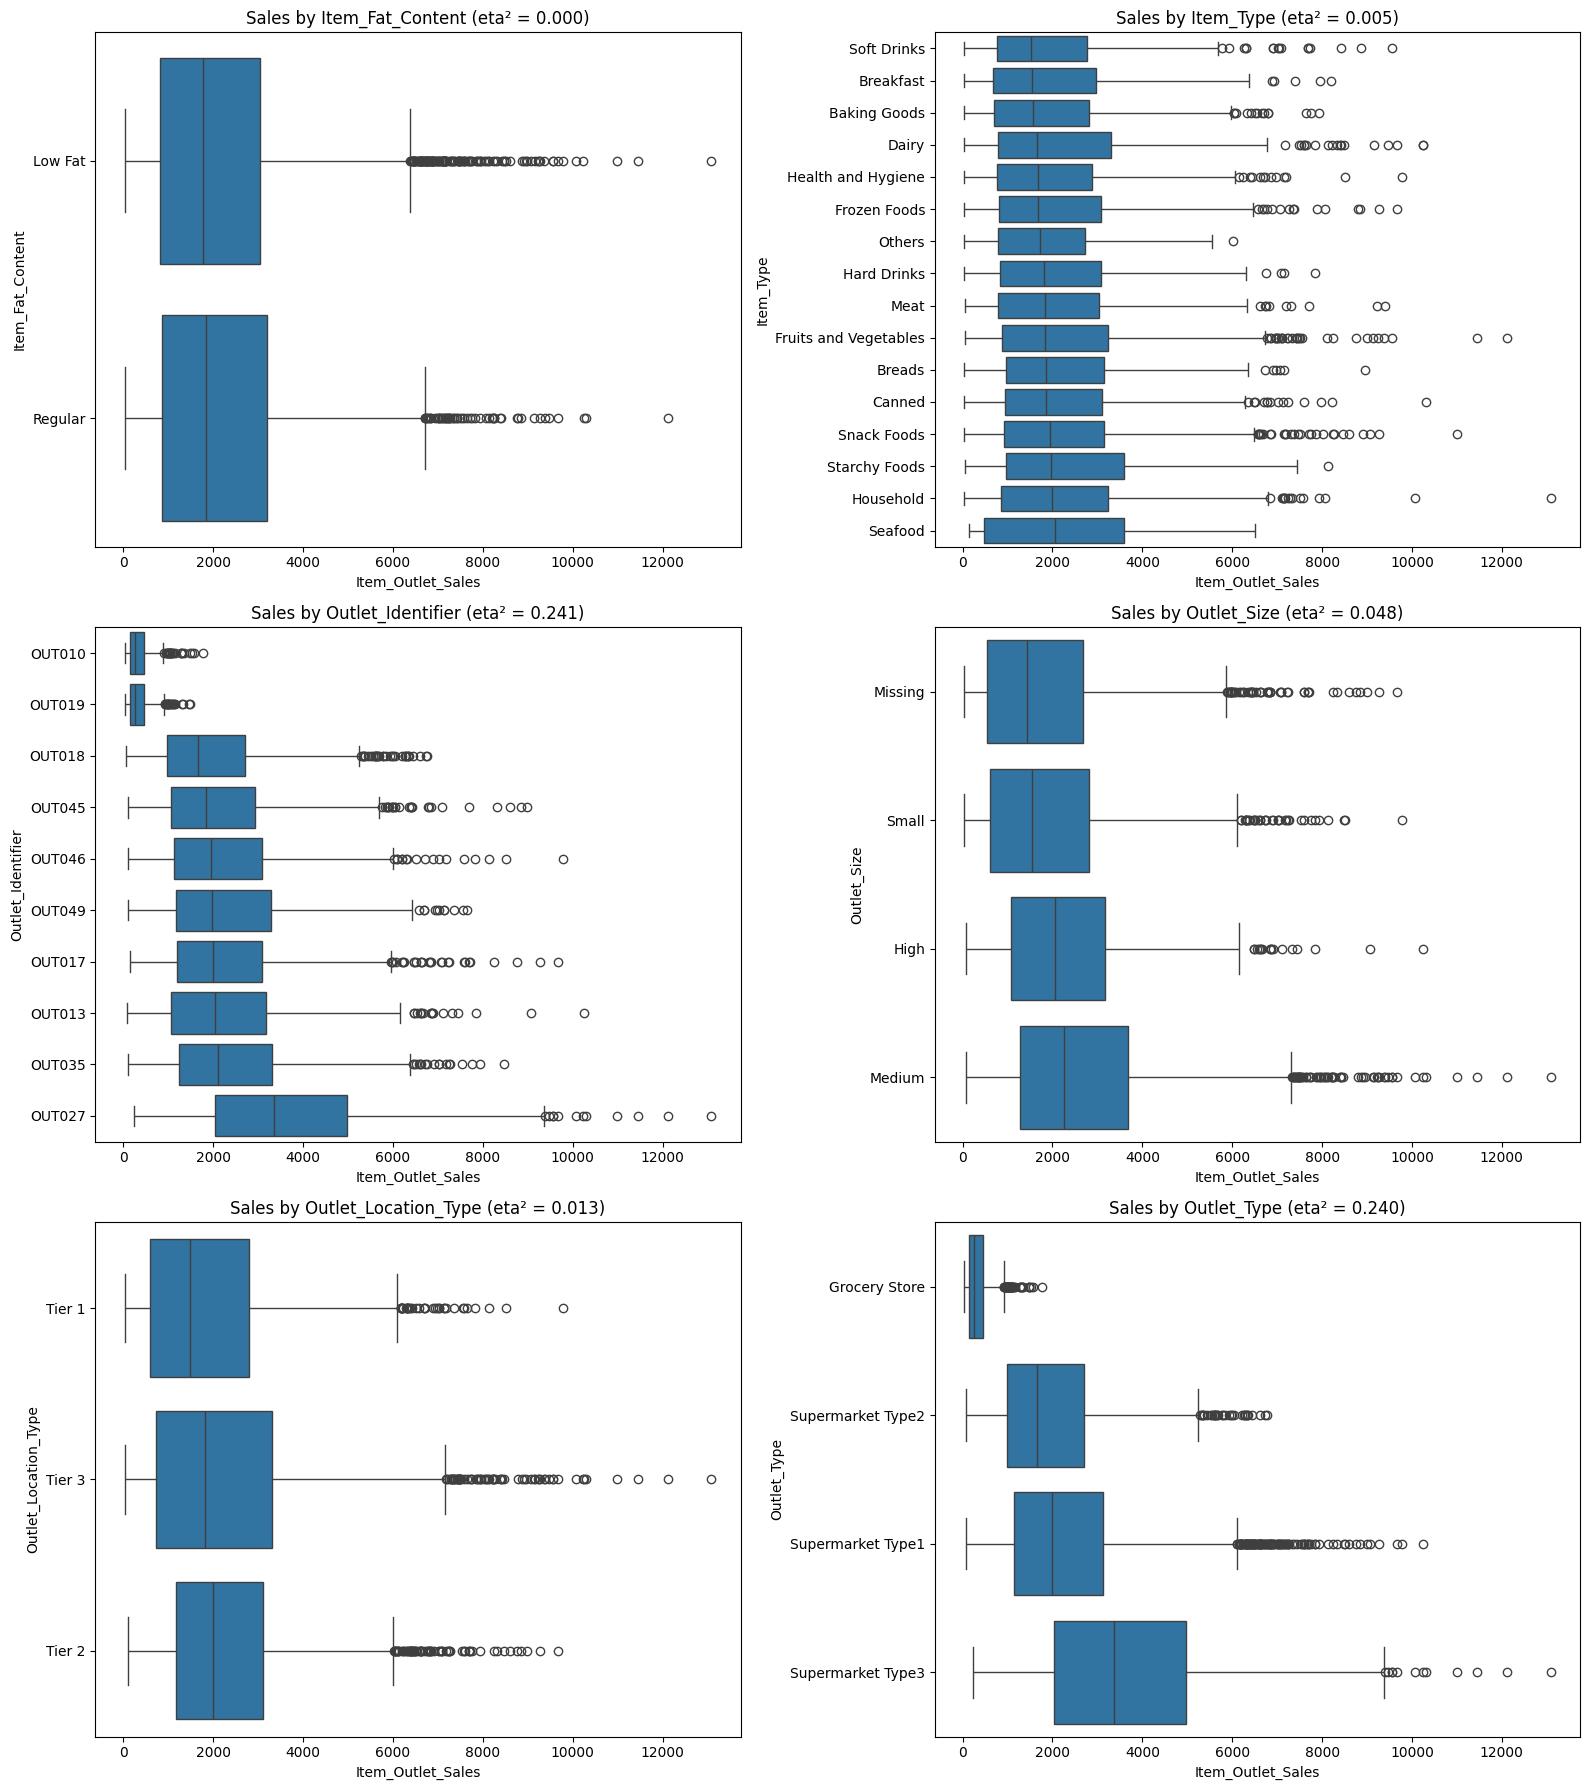

In [90]:
output.no_vertical_scroll()
#categorical features v/s sales
eda = train.copy()   # EDA only copy
eda['Item_Fat_Content'] = eda['Item_Fat_Content'].replace(
    {'LF': 'Low Fat', 'low fat': 'Low Fat', 'reg': 'Regular'})
eda['Outlet_Size'] = eda['Outlet_Size'].fillna('Missing')   # showing missing as its own group

cat_cols = ['Item_Fat_Content', 'Item_Type', 'Outlet_Identifier',
            'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type']

def eta_squared(cat, y):
    """Share of sales variance explained by the groups (0 = none, 1 = all)."""
    grand = y.mean()
    ss_between = y.groupby(cat).apply(lambda g: len(g) * (g.mean() - grand) ** 2).sum()
    ss_total = ((y - grand) ** 2).sum()
    return ss_between / ss_total

eta = pd.Series({c: eta_squared(eda[c], eda[target]) for c in cat_cols}).sort_values(ascending=False)
print('Eta squared (strength of each categorical feature vs sales):')
display(eta.round(3))

for col in cat_cols:
    print(f'\n{col}')
    display(eda.groupby(col)[target].agg(['count', 'mean', 'median'])
               .sort_values('mean', ascending=False).round(1))

fig, axes = plt.subplots(3, 2, figsize=(16, 18))
for ax, col in zip(axes.flat, cat_cols):
    order = eda.groupby(col)[target].median().sort_values().index
    sns.boxplot(data=eda, y=col, x=target, order=order, ax=ax)
    ax.set_title(f'Sales by {col} (eta² = {eta[col]:.3f})')
plt.tight_layout()
plt.show()

##Categorical features vs sales

1. Store-level features explain the most variance. Outlet_Identifier has η² = 0.241 and Outlet_Type η² = 0.240. Outlet_Type alone captures almost all of the store effect.
2. Grocery stores sell about 7–10 times less than supermarkets (about 340 vs 2000–3700). Supermarket Type3 (OUT027) sells most. The order (Type3 > Type1 > Type2 > Grocery) doesn’t follow the type numbers, so Outlet_Type is nominal.
3. Outlet_Size has a small effect (η² = 0.048, with Medium highest). Location (0.013), Item_Type (0.005) and Fat content (0.000) have almost no effect on their own.
4. Overall, sales are driven mainly by price (MRP) and store type. Product attributes other than price contribute very little.

<IPython.core.display.Javascript object>

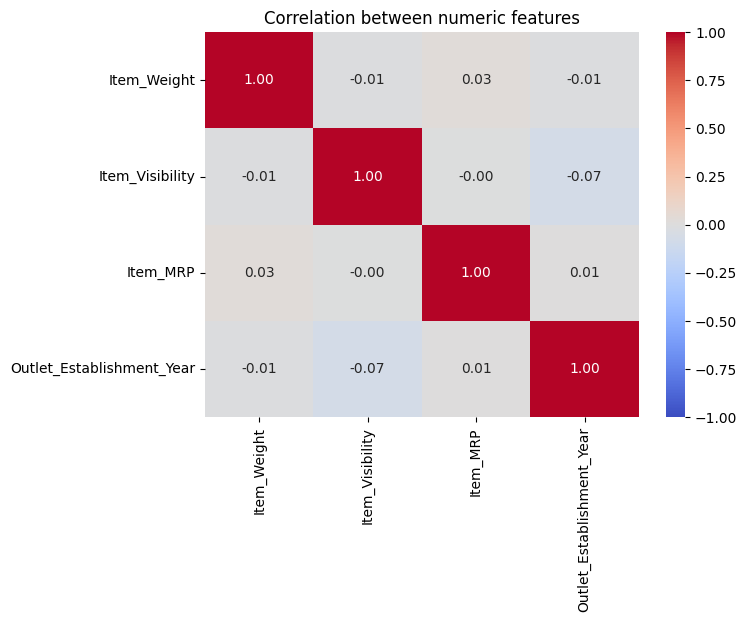

,feature,VIF
0,Item_Weight,1.0
1,Item_Visibility,1.0
2,Item_MRP,1.0
3,Outlet_Establishment_Year,1.0


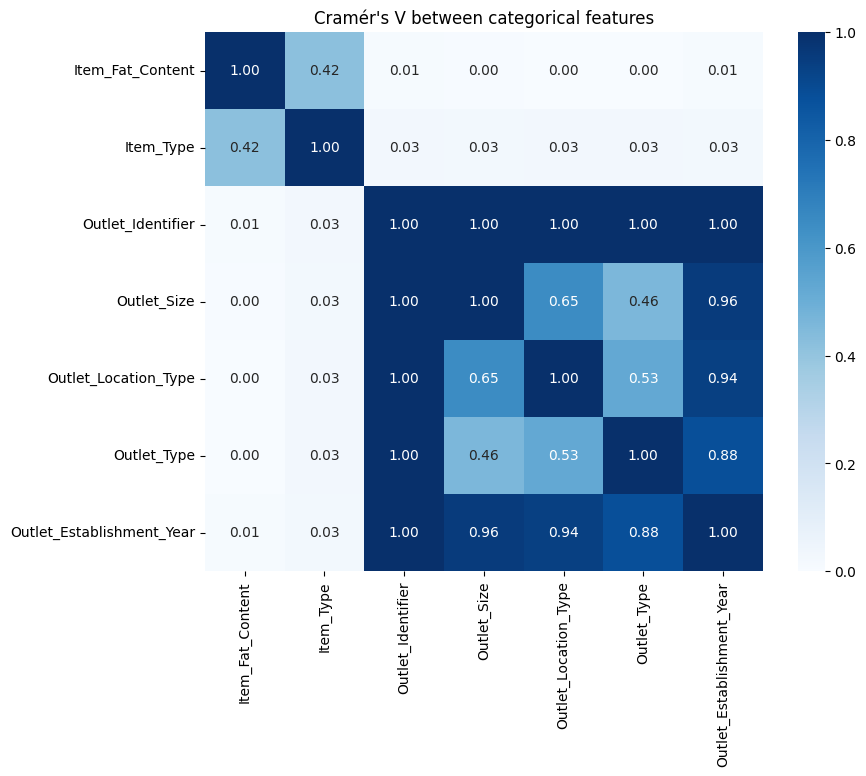

In [91]:
output.no_vertical_scroll()
#multicollinearity
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from scipy.stats import chi2_contingency

# 1. Correlation between numeric features
plt.figure(figsize=(7, 5))
sns.heatmap(train[num_feats].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between numeric features')
plt.show()

# 2. VIF (rows with missing weight are skipped)
Xv = add_constant(train[num_feats].dropna())
vif = pd.DataFrame({'feature': num_feats,
                    'VIF': [variance_inflation_factor(Xv.values, i + 1) for i in range(len(num_feats))]})
display(vif.round(2))

# 3. Cramér's V between categorical features
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    chi2 = chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

cv_cols = cat_cols + ['Outlet_Establishment_Year']   # year treated as a category here
cv = pd.DataFrame(index=cv_cols, columns=cv_cols, dtype=float)
for a in cv_cols:
    for b in cv_cols:
        cv.loc[a, b] = cramers_v(eda[a], eda[b])

plt.figure(figsize=(9, 7))
sns.heatmap(cv, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1)
plt.title("Cramér's V between categorical features")
plt.show()

##Multicollinearity

1. There’s no multicollinearity among the numeric features. All correlations are near 0 and every VIF is 1.0.
2. The store attributes are fully redundant with Outlet_Identifier (Cramér’s V = 1.00), because each store has one fixed size, location, type and year. Year is also strongly tied to Size, Location and Type (0.88–0.96).
3. Fat content and Item_Type are moderately associated (Cramér’s V = 0.42).

Interpretation
* In linear regression, don’t use Outlet_Identifier together with all the store attributes
* In tree models, predictions are not impacted, but feature importance gets split across the redundant columns.

In [92]:
# Do non-food items carry fat labels?
print(pd.crosstab(eda['Item_Identifier'].str[:2], eda['Item_Fat_Content']))
print("\n")
print(pd.crosstab(eda['Item_Type'], eda['Item_Fat_Content']))

Item_Fat_Content  Low Fat  Regular
Item_Identifier                   
DR                    728       71
FD                   3190     2935
NC                   1599        0


Item_Fat_Content       Low Fat  Regular
Item_Type                              
Baking Goods               329      319
Breads                     140      111
Breakfast                   41       69
Canned                     341      308
Dairy                      418      264
Frozen Foods               450      406
Fruits and Vegetables      630      602
Hard Drinks                214        0
Health and Hygiene         520        0
Household                  910        0
Meat                       170      255
Others                     169        0
Seafood                     37       27
Snack Foods                692      508
Soft Drinks                374       71
Starchy Foods               82       66


1599 non-consumable (NC) items carry a fake “Low Fat” label. These are Household, Health and Hygiene, and Others. We’ll relabel them as Non-Edible.

In [93]:
# Is visibility higher in grocery stores?
display(eda[eda['Item_Visibility'] > 0]
          .groupby('Outlet_Type')['Item_Visibility'].agg(['count', 'mean', 'median']).round(4))

,count,mean,median
Outlet_Type,,,
Grocery Store,1024,0.1109,0.0973
Supermarket Type1,5235,0.0647,0.0545
Supermarket Type2,863,0.0656,0.0546
Supermarket Type3,875,0.0626,0.0530



grocery stores give items a bigger display share. This explains the visibility outliers. It also motivates a Visibility_Ratio feature: an item’s visibility relative to its own average, which removes the store effect.

# Data quality
1. Missing values by store: the missing share of Item_Weight and Outlet_Size per store, to test whether the missing values are systematic or random
2. Store profile table: one row per store, to see which stores lack Outlet_Size and what similar stores look like.

In [94]:
#Missing values by store
miss = (train.groupby('Outlet_Identifier')[['Item_Weight', 'Outlet_Size']]
             .apply(lambda d: d.isnull().mean() * 100)
             .round(1))
miss['Visibility_zero_%'] = (train.groupby('Outlet_Identifier')['Item_Visibility']
                                  .apply(lambda s: (s == 0).mean() * 100).round(1))
display(miss)   # % of rows missing per store

,Item_Weight,Outlet_Size,Visibility_zero_%
Outlet_Identifier,,,
OUT010,0.0,100.0,5.2
OUT013,0.0,0.0,6.3
OUT017,0.0,100.0,6.2
OUT018,0.0,0.0,7.0
OUT019,100.0,0.0,5.7
OUT027,100.0,0.0,6.4
OUT035,0.0,0.0,5.8
OUT045,0.0,100.0,6.2
OUT046,0.0,0.0,6.6


In [95]:
# Check that each store has exactly one value per attribute
store_attrs = ['Outlet_Establishment_Year', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type']
print('Max distinct values per store:')
print(train.groupby('Outlet_Identifier')[store_attrs].nunique().max())

profile = (train.groupby('Outlet_Identifier')
                .agg(Year=('Outlet_Establishment_Year', 'first'),
                     Size=('Outlet_Size', 'first'),
                     Location=('Outlet_Location_Type', 'first'),
                     Type=('Outlet_Type', 'first'),
                     Rows=(target, 'size'),
                     Mean_Sales=(target, 'mean'),
                     Mean_Visibility=('Item_Visibility', 'mean'))
                .sort_values(['Type', 'Location']))
display(profile.round(3))

# Known sizes by Type and Location, to guide filling the missing ones
print(pd.crosstab([profile['Type'], profile['Location']], profile['Size'].fillna('Missing')))

Max distinct values per store:
Outlet_Establishment_Year    1
Outlet_Size                  1
Outlet_Location_Type         1
Outlet_Type                  1
dtype: int64


,Year,Size,Location,Type,Rows,Mean_Sales,Mean_Visibility
Outlet_Identifier,,,,,,,
OUT019,1985,Small,Tier 1,Grocery Store,528,340.330,0.108
OUT010,1998,None,Tier 3,Grocery Store,555,339.352,0.101
OUT046,1997,Small,Tier 1,Supermarket Type1,930,2277.844,0.060
OUT049,1999,Medium,Tier 1,Supermarket Type1,930,2348.355,0.061
OUT017,2007,None,Tier 2,Supermarket Type1,926,2340.675,0.061
OUT035,2004,Small,Tier 2,Supermarket Type1,930,2438.842,0.061
OUT045,2002,None,Tier 2,Supermarket Type1,929,2192.385,0.060
OUT013,1987,High,Tier 3,Supermarket Type1,932,2298.995,0.060
OUT018,2009,Medium,Tier 3,Supermarket Type2,928,1995.499,0.061


Size                        High  Medium  Missing  Small
Type              Location                              
Grocery Store     Tier 1       0       0        0      1
                  Tier 3       0       0        1      0
Supermarket Type1 Tier 1       0       1        0      1
                  Tier 2       0       0        2      1
                  Tier 3       1       0        0      0
Supermarket Type2 Tier 3       0       1        0      0
Supermarket Type3 Tier 3       0       1        0      0


In [96]:
known_w = train.dropna(subset=['Item_Weight']).groupby('Item_Identifier')['Item_Weight']

# 1. Weight
miss_w_items = train.loc[train['Item_Weight'].isnull(), 'Item_Identifier'].unique()
print('Items with a missing weight:', len(miss_w_items))
print('From these items which have a known weight elsewhere in train:',
      pd.Series(miss_w_items).isin(known_w.size().index).sum())

# Is weight constant per item? (justifies borrowing it)
print('Items whose known weight varies across stores:', (known_w.nunique() > 1).sum())

# 2. Visibility zeros
nz = train[train['Item_Visibility'] > 0].groupby('Item_Identifier')['Item_Visibility']
zero_items = train.loc[train['Item_Visibility'] == 0, 'Item_Identifier'].unique()
print('\nItems with a zero visibility:', len(zero_items))
print('From these items which have a non-zero visibility elsewhere in train:',
      pd.Series(zero_items).isin(nz.size().index).sum())

Items with a missing weight: 1142
From these items which have a known weight elsewhere in train: 1138
Items whose known weight varies across stores: 0

Items with a zero visibility: 446
From these items which have a non-zero visibility elsewhere in train: 446


#Data quality conclusions

#Missing values

1. The gaps are whole-store reporting failures.
2. Item_Weight is 100% missing in OUT019 and OUT027, and 0% everywhere else.
3. Outlet_Size is 100% missing in OUT010, OUT017 and OUT045, and 0% everywhere else.
This matches what wour findings from the row counts in Section A.
4. Visibility zeros are spread evenly across all stores (5–7% each). They aren’t a store-level failure, but scattered recording errors.
5. Both stores (OUT019 and OUT027) missing weights were established in 1985. That’s possibly the same old system failing.

#Store profile

1. Each store has exactly one value for each attribute (max distinct = 1). This proves the Cramér’s V = 1 from Section B is structural, not a coincidence.
2. We can fill Outlet_Size by matching store type and location:
OUT010 (Grocery, Tier 3): the only other grocery store, OUT019, is Small, and grocery stores are small by nature. So Small.
OUT017 and OUT045 (Supermarket Type1, Tier 2): the only known store with that exact profile, OUT035, is Small. So Small.
Decision: fill all three with Small.
3. Most common size is median but filling size with reference to outlet_Type and location keeps stores characteris close to real.
4. The grocery stores have the lowest sales and the highest visibility (about 0.10–0.11).
OUT027 (Type3) is the top seller (3694).
All the supermarkets have similar visibility (about 0.06).


* Weight is a fixed product property. No item’s known weight varies across stores, so taking it from the same item is correct.
* 1138 of the 1142 items with a missing weight can be recovered from other train rows. For the 4 remaining items, the fallback is the median weight of their Item_Type. That’s better than the overall median, because it keeps similar products together.
* All 446 items with a zero visibility have a non-zero visibility elsewhere in train. So every zero can be replaced with that item’s average non-zero visibility.

#Data cleaning
1. Fat content has 5 inconsistent labels so map LF and low fat to Low Fat, and reg to Regular.
2. All 1599 NC items carry a fake “Low Fat” label so relabel them Non-Edible.
3. Item_Weight is missing for whole stores (OUT019, OUT027) but is constant per item so fill with the same item’s weight from train (exact recovery). For the 4 unrecoverable items, and any test item without a known weight, use the Item_Type median from train.
4. The 526 visibility zeros are disguised missing values (their sales match normal items, and they’re spread evenly across stores) so replace each with the item’s mean non-zero visibility from train, and add a Visibility_Was_Zero flag.
5. Outlet_Size is missing for whole stores (OUT010, OUT017, OUT045) so fill with Small, matched on store type and location, not the overall mode.
6. The outliers in sales and visibility are genuine so keep them all, with no removal or capping.
7. Every imputed value (item weights, item visibilities, medians) is computed from train only and then applied to test.

In [97]:
train_clean = train.copy()
test_clean  = test.copy()

print('train_clean:', train_clean.shape, '\ntest_clean:', test_clean.shape)
print('\nMissing before cleaning train:', train_clean.isnull().sum())
print('\nMissing before cleaning test :', test_clean.isnull().sum())
print('\nZero visibility before train:', (train_clean['Item_Visibility'] == 0).sum(),
      '\ntest:', (test_clean['Item_Visibility'] == 0).sum())

train_clean: (8523, 12) 
test_clean: (5681, 11)

Missing before cleaning train: Item_Identifier                 0
Item_Weight                  1463
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  2410
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales               0
dtype: int64

Missing before cleaning test : Item_Identifier                 0
Item_Weight                   976
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  1606
Outlet_Location_Type            0
Outlet_Type                     0
dtype: int64

Zero visibility before train: 526 
test: 353


In [98]:
#Fix inconsistent Item_Fat_Content labels
fat_map = {'LF': 'Low Fat', 'low fat': 'Low Fat', 'reg': 'Regular'}

for name, df in [('train', train_clean), ('test', test_clean)]:
    df['Item_Fat_Content'] = df['Item_Fat_Content'].replace(fat_map)
    print(f'{name}:', df['Item_Fat_Content'].value_counts().to_dict())

train: {'Low Fat': 5517, 'Regular': 3006}
test: {'Low Fat': 3668, 'Regular': 2013}


In [99]:
# Non-consumable (NC) items cannot have a fat content
for name, df in [('train', train_clean), ('test', test_clean)]:
    is_nc = df['Item_Identifier'].str.startswith('NC')
    df.loc[is_nc, 'Item_Fat_Content'] = 'Non-Edible'
    print(f'\n{name}:')
    print(pd.crosstab(df['Item_Identifier'].str[:2], df['Item_Fat_Content']))


train:
Item_Fat_Content  Low Fat  Non-Edible  Regular
Item_Identifier                               
DR                    728           0       71
FD                   3190           0     2935
NC                      0        1599        0

test:
Item_Fat_Content  Low Fat  Non-Edible  Regular
Item_Identifier                               
DR                    480           0       38
FD                   2101           0     1975
NC                      0        1087        0


In [100]:
# Fill Item_Weight
item_weight        = train_clean.groupby('Item_Identifier')['Item_Weight'].mean()  # weight is constant per item
type_median_weight = train_clean.groupby('Item_Type')['Item_Weight'].median()

for name, df in [('train', train_clean), ('test', test_clean)]:
    before = df['Item_Weight'].isnull().sum()
    df['Item_Weight'] = df['Item_Weight'].fillna(df['Item_Identifier'].map(item_weight))
    after_item = df['Item_Weight'].isnull().sum()
    df['Item_Weight'] = df['Item_Weight'].fillna(df['Item_Type'].map(type_median_weight))
    after_type = df['Item_Weight'].isnull().sum()
    print(f'\n{name}: \nmissing {before}\nfilled from same item: {before - after_item}'
          f'\nfilled from Item_Type median: {after_item - after_type} \nstill missing: {after_type}')

# Sanity check: every item should still have exactly one weight in train
print('\nMax distinct weights per item (train):',
      train_clean.groupby('Item_Identifier')['Item_Weight'].nunique().max())


train: 
missing 1463
filled from same item: 1459
filled from Item_Type median: 4 
still missing: 0

test: 
missing 976
filled from same item: 975
filled from Item_Type median: 1 
still missing: 0

Max distinct weights per item (train): 2


In [101]:
# Replace disguised-missing zero visibilities
nonzero_train   = train_clean[train_clean['Item_Visibility'] > 0]
item_vis        = nonzero_train.groupby('Item_Identifier')['Item_Visibility'].mean()
type_median_vis = nonzero_train.groupby('Item_Type')['Item_Visibility'].median()   # fallback

for name, df in [('train', train_clean), ('test', test_clean)]:
    zero = df['Item_Visibility'] == 0
    df.loc[zero, 'Item_Visibility'] = df.loc[zero, 'Item_Identifier'].map(item_vis)
    from_item = zero.sum() - df['Item_Visibility'].isnull().sum()
    df['Item_Visibility'] = df['Item_Visibility'].fillna(df['Item_Type'].map(type_median_vis))
    print(f'\n{name}:\nzeros {zero.sum()} \nfilled from same item: {from_item}'
          f'\nfrom Item_Type median: {zero.sum() - from_item}'
          f'\nzeros left: {(df["Item_Visibility"] == 0).sum()} \nmissing: {df["Item_Visibility"].isnull().sum()}')

print('\nVisibility after cleaning (train):')
print(train_clean['Item_Visibility'].describe().round(4))


train:
zeros 526 
filled from same item: 526
from Item_Type median: 0
zeros left: 0 
missing: 0

test:
zeros 353 
filled from same item: 353
from Item_Type median: 0
zeros left: 0 
missing: 0

Visibility after cleaning (train):
count    8523.0000
mean        0.0707
std         0.0503
min         0.0036
25%         0.0314
50%         0.0581
75%         0.0989
max         0.3284
Name: Item_Visibility, dtype: float64


In [102]:
# Fill Outlet_Size by matching similar stores
store = train_clean.groupby('Outlet_Identifier')[['Outlet_Type', 'Outlet_Location_Type', 'Outlet_Size']].first()
known = store.dropna(subset=['Outlet_Size'])

size_fill = {}
for oid, row in store[store['Outlet_Size'].isnull()].iterrows():
    match = known[(known['Outlet_Type'] == row['Outlet_Type']) &
                  (known['Outlet_Location_Type'] == row['Outlet_Location_Type'])]
    rule = 'same Type + Location'
    if match.empty:
        match = known[known['Outlet_Type'] == row['Outlet_Type']]
        rule = 'same Type'
    size_fill[oid] = match['Outlet_Size'].mode()[0]
    print(f"{oid} ({row['Outlet_Type']}, {row['Outlet_Location_Type']}) \n{size_fill[oid]}"
          f"  [{rule}: matched {list(match.index)}]")

for name, df in [('train', train_clean), ('test', test_clean)]:
    miss = df['Outlet_Size'].isnull()
    df.loc[miss, 'Outlet_Size'] = df.loc[miss, 'Outlet_Identifier'].map(size_fill)
    print(f'\n{name}: \nfilled {miss.sum()}\nstill missing: {df["Outlet_Size"].isnull().sum()}')

print(train_clean['Outlet_Size'].value_counts().to_dict())

OUT010 (Grocery Store, Tier 3) 
Small  [same Type: matched ['OUT019']]
OUT017 (Supermarket Type1, Tier 2) 
Small  [same Type + Location: matched ['OUT035']]
OUT045 (Supermarket Type1, Tier 2) 
Small  [same Type + Location: matched ['OUT035']]

train: 
filled 2410
still missing: 0

test: 
filled 1606
still missing: 0
{'Small': 4798, 'Medium': 2793, 'High': 932}


#Feature engineering

8. Item ID prefix (FD/DR/NC) groups products cleanly, while Item_Type is sparse so add Item_Category (Food, Drinks, Non-Consumable).
9. Establishment year is a store label, not a trend so convert it to Outlet_Age = 2013 − year.
10. Visibility depends on store type (grocery stores give a bigger display share) so add Visibility_Ratio = an item’s visibility divided by its mean visibility in train. It shows whether the item gets more display space than usual.
11. MRP falls into 4 clear price clusters so add MRP_Band (4 bands, with cut points around 69, 136 and 203).

- eta_sq: measures how much of the variation in sales a categorical feature explains, from 0 (nothing) to 1 (everything).
- check_numeric: gives the correlation of a numeric feature with sales.
- check_categorical: gives the η² of a categorical feature.
- demean_by_store: removes each store’s average, so we can see whether a feature still relates to sales within the same store.
- store_level: flags features that have one fixed value per store, where the within-store check doesn’t apply.

In [103]:
# Item_Category from the ID prefix
cat_map = {'FD': 'Food', 'DR': 'Drinks', 'NC': 'Non-Consumable'}
for df in (train_clean, test_clean):
    df['Item_Category'] = df['Item_Identifier'].str[:2].map(cat_map)

print('Counts (train):', train_clean['Item_Category'].value_counts().to_dict())
print('Unmapped (train/test):', train_clean['Item_Category'].isnull().sum(), '/', test_clean['Item_Category'].isnull().sum())
print('\nHow Item_Type maps into Item_Category (train):')
print(pd.crosstab(train_clean['Item_Type'], train_clean['Item_Category']))

# Usefulness check
display(train_clean.groupby('Item_Category')[target].agg(['count', 'mean', 'median']).round(1))

Counts (train): {'Food': 6125, 'Non-Consumable': 1599, 'Drinks': 799}
Unmapped (train/test): 0 / 0

How Item_Type maps into Item_Category (train):
Item_Category          Drinks  Food  Non-Consumable
Item_Type                                          
Baking Goods                0   648               0
Breads                      0   251               0
Breakfast                   0   110               0
Canned                      0   649               0
Dairy                     140   542               0
Frozen Foods                0   856               0
Fruits and Vegetables       0  1232               0
Hard Drinks               214     0               0
Health and Hygiene          0     0             520
Household                   0     0             910
Meat                        0   425               0
Others                      0     0             169
Seafood                     0    64               0
Snack Foods                 0  1200               0
Soft Drinks          

,count,mean,median
Item_Category,,,
Drinks,799,1997.3,1496.7
Food,6125,2215.4,1811.0
Non-Consumable,1599,2142.7,1874.9


In [104]:
# Outlet_Age
for df in (train_clean, test_clean):
    df['Outlet_Age'] = 2013 - df['Outlet_Establishment_Year']   # data is from 2013

display(train_clean.groupby('Outlet_Identifier')
                   .agg(Year=('Outlet_Establishment_Year', 'first'), Age=('Outlet_Age', 'first'),
                        Type=('Outlet_Type', 'first'), Mean_Sales=(target, 'mean'))
                   .sort_values('Age').round(1))

,Year,Age,Type,Mean_Sales
Outlet_Identifier,,,,
OUT018,2009,4,Supermarket Type2,1995.5
OUT017,2007,6,Supermarket Type1,2340.7
OUT035,2004,9,Supermarket Type1,2438.8
OUT045,2002,11,Supermarket Type1,2192.4
OUT049,1999,14,Supermarket Type1,2348.4
OUT010,1998,15,Grocery Store,339.4
OUT046,1997,16,Supermarket Type1,2277.8
OUT013,1987,26,Supermarket Type1,2299.0
OUT019,1985,28,Grocery Store,340.3


In [105]:
# MRP_Band from the 4 price clusters
mrp_cuts   = [69, 136, 203]
mrp_bins   = [0] + mrp_cuts + [np.inf]
mrp_labels = ['Low', 'Medium', 'High', 'Very High']

# Confirm the cut points sit in the empty gaps between clusters
for c in mrp_cuts:
    near = train_clean['Item_MRP'].between(c - 2, c + 2).sum()
    print(f'Rows with MRP within +/-2 of {c}: {near}')

for df in (train_clean, test_clean):
    df['MRP_Band'] = pd.cut(df['Item_MRP'], bins=mrp_bins, labels=mrp_labels)

display(train_clean.groupby('MRP_Band', observed=True)
                   .agg(rows=('Item_MRP', 'size'), mrp_min=('Item_MRP', 'min'), mrp_max=('Item_MRP', 'max'),
                        mean_sales=(target, 'mean')).round(1))

Rows with MRP within +/-2 of 69: 2
Rows with MRP within +/-2 of 136: 3
Rows with MRP within +/-2 of 203: 2


,rows,mrp_min,mrp_max,mean_sales
MRP_Band,,,,
Low,1341,31.3,67.5,736.5
Medium,2751,71.3,134.5,1615.6
High,3002,138.1,201.1,2631.2
Very High,1429,205.0,266.9,3680.8


In [106]:
# Visibility_Ratio
item_mean_vis = train_clean.groupby('Item_Identifier')['Item_Visibility'].mean()

for df in (train_clean, test_clean):
    df['Visibility_Ratio'] = df['Item_Visibility'] / df['Item_Identifier'].map(item_mean_vis)
    df['Visibility_Ratio'] = df['Visibility_Ratio'].fillna(1.0)   # unseen item -> "average display"

print('Visibility_Ratio (train):')
print(train_clean['Visibility_Ratio'].describe().round(3))

# Does the ratio still encode the store type?
display(train_clean.groupby('Outlet_Type')['Visibility_Ratio'].agg(['mean', 'median']).round(3))


Visibility_Ratio (train):
count    8523.000
mean        1.000
std         0.186
min         0.678
25%         0.890
50%         0.997
75%         1.001
max         1.615
Name: Visibility_Ratio, dtype: float64


,mean,median
Outlet_Type,,
Grocery Store,1.440,1.474
Supermarket Type1,0.937,0.922
Supermarket Type2,0.938,0.925
Supermarket Type3,0.929,0.909


#Encode and build feature sets
12. Outlet_Type is nominal. Use one-hot encoding for linear regression and the category type for tree models.
13. Item_Identifier has 1559 levels so I will not use it as a raw feature, to avoid overfitting. Use only what we derive from it (Item_Category).
14. The store attributes are fully determined by Outlet_Identifier (Cramér’s V = 1) so in
Linear model use Outlet_Identifier alone, one-hot with one category dropped, and leave out size, location, type and age. This avoids perfect collinearity.
For Tree mo,dels keep all of them. Predictions are unaffected.
15. Weight, fat content and Item_Type show almost no relationship with sales

In [107]:
# Target and feature sets for each model family
y = train_clean[target].copy()

# Tree models (LightGBM, XGBoost, CatBoost): all informative features, store attributes included
tree_num = ['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Outlet_Age', 'Visibility_Ratio']
tree_cat = ['Item_Fat_Content', 'Item_Type', 'Outlet_Identifier', 'Outlet_Size',
            'Outlet_Location_Type', 'Outlet_Type', 'Item_Category', 'MRP_Band']
tree_features = tree_num + tree_cat

# Linear model (Ridge): the store is captured by Outlet_Identifier only
lin_num = ['Item_MRP', 'Item_Weight', 'Item_Visibility', 'Visibility_Ratio']
lin_cat = ['Outlet_Identifier', 'Item_Fat_Content', 'Item_Category', 'MRP_Band']

not_model_inputs = [c for c in train_clean.columns if c not in tree_features + [target]]
print('Tree features  :', len(tree_features), tree_features)
print('Linear features:', len(lin_num + lin_cat), lin_num + lin_cat)
print('Kept in data but not a model input:', not_model_inputs)

Tree features  : 13 ['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Outlet_Age', 'Visibility_Ratio', 'Item_Fat_Content', 'Item_Type', 'Outlet_Identifier', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type', 'Item_Category', 'MRP_Band']
Linear features: 8 ['Item_MRP', 'Item_Weight', 'Item_Visibility', 'Visibility_Ratio', 'Outlet_Identifier', 'Item_Fat_Content', 'Item_Category', 'MRP_Band']
Kept in data but not a model input: ['Item_Identifier', 'Outlet_Establishment_Year']


- `Item_Identifier`: 1559 levels. It would let the model memorise individual products and overfit (decision 13). Its useful part is already in Item_Category.
- `Outlet_Establishment_Year`: identical information to `Outlet_Age`.

In [108]:
# Category encoding for tree models
def to_category(train_df, test_df, cols):
    tr, te = train_df.copy(), test_df.copy()
    for c in cols:
        cats = pd.Categorical(tr[c].astype(str)).categories
        tr[c] = pd.Categorical(tr[c].astype(str), categories=cats)
        te[c] = pd.Categorical(te[c].astype(str), categories=cats)   # unseen test category -> NaN
    return tr, te

X_tree, X_tree_test = to_category(train_clean[tree_features], test_clean[tree_features], tree_cat)

print('X_tree:', X_tree.shape, '\nX_tree_test:', X_tree_test.shape)
print('Test categories unseen in train (become NaN):', int(X_tree_test[tree_cat].isnull().sum().sum()))
display(X_tree.dtypes.to_frame('dtype').T)

X_tree: (8523, 13) 
X_tree_test: (5681, 13)
Test categories unseen in train (become NaN): 0


,Item_Weight,Item_Visibility,Item_MRP,Outlet_Age,Visibility_Ratio,Item_Fat_Content,Item_Type,Outlet_Identifier,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Category,MRP_Band
dtype,float64,float64,float64,int64,float64,category,category,category,category,category,category,category,category


- Converted every categorical tree feature to pandas `category` dtype. The list of categories comes **from train only**, and test uses exactly the same list.
- LightGBM and XGBoost can split directly on categorical columns once they have `category` dtype.

In [109]:
# Mixed encoding: label for Outlet_Identifier & Item_Type, one-hot for the rest (learned from TRAIN only)
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

label_cols  = ['Outlet_Identifier', 'Item_Type']
onehot_cols = ['Item_Fat_Content', 'Outlet_Size', 'Outlet_Location_Type',
               'Outlet_Type', 'Item_Category', 'MRP_Band']
num_cols_enc = ['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Outlet_Age', 'Visibility_Ratio']

# 1. Label encoding
label_encoders = {}
lab_train, lab_test = pd.DataFrame(index=train_clean.index), pd.DataFrame(index=test_clean.index)
for col in label_cols:
    le = LabelEncoder().fit(train_clean[col].astype(str))
    lab_train[f'{col}_LE'] = le.transform(train_clean[col].astype(str))
    lab_test[f'{col}_LE']  = le.transform(test_clean[col].astype(str))
    label_encoders[col] = le
    print(f'{col}:', dict(zip(le.classes_, range(len(le.classes_)))))

# 2. One-hot encoding
ohe = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
ohe.fit(train_clean[onehot_cols].astype(str))
ohe_names = ohe.get_feature_names_out(onehot_cols)
oh_train = pd.DataFrame(ohe.transform(train_clean[onehot_cols].astype(str)), columns=ohe_names, index=train_clean.index)
oh_test  = pd.DataFrame(ohe.transform(test_clean[onehot_cols].astype(str)),  columns=ohe_names, index=test_clean.index)
print('\nReference (dropped) category per one-hot feature:',
      dict(zip(onehot_cols, [c[0] for c in ohe.categories_])))

# 3. Final encoded tables: numeric + label-encoded + one-hot
X_enc      = pd.concat([train_clean[num_cols_enc], lab_train, oh_train], axis=1)
X_enc_test = pd.concat([test_clean[num_cols_enc],  lab_test,  oh_test],  axis=1)

print('\nX_enc:', X_enc.shape, '\nX_enc_test:', X_enc_test.shape)
print('Same columns in train and test:', list(X_enc.columns) == list(X_enc_test.columns))
display(X_enc.head())
X_enc.info()

Outlet_Identifier: {'OUT010': 0, 'OUT013': 1, 'OUT017': 2, 'OUT018': 3, 'OUT019': 4, 'OUT027': 5, 'OUT035': 6, 'OUT045': 7, 'OUT046': 8, 'OUT049': 9}
Item_Type: {'Baking Goods': 0, 'Breads': 1, 'Breakfast': 2, 'Canned': 3, 'Dairy': 4, 'Frozen Foods': 5, 'Fruits and Vegetables': 6, 'Hard Drinks': 7, 'Health and Hygiene': 8, 'Household': 9, 'Meat': 10, 'Others': 11, 'Seafood': 12, 'Snack Foods': 13, 'Soft Drinks': 14, 'Starchy Foods': 15}

Reference (dropped) category per one-hot feature: {'Item_Fat_Content': 'Low Fat', 'Outlet_Size': 'High', 'Outlet_Location_Type': 'Tier 1', 'Outlet_Type': 'Grocery Store', 'Item_Category': 'Drinks', 'MRP_Band': 'High'}

X_enc: (8523, 21) 
X_enc_test: (5681, 21)
Same columns in train and test: True


,Item_Weight,Item_Visibility,Item_MRP,Outlet_Age,Visibility_Ratio,Outlet_Identifier_LE,Item_Type_LE,Item_Fat_Content_Non-Edible,Item_Fat_Content_Regular,Outlet_Size_Medium,...,Outlet_Location_Type_Tier 2,Outlet_Location_Type_Tier 3,Outlet_Type_Supermarket Type1,Outlet_Type_Supermarket Type2,Outlet_Type_Supermarket Type3,Item_Category_Food,Item_Category_Non-Consumable,MRP_Band_Low,MRP_Band_Medium,MRP_Band_Very High
0,9.30,0.016047,249.8092,14,0.922960,9,4,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,5.92,0.019278,48.2692,4,1.003057,3,14,0.0,1.0,1.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,17.50,0.016760,141.6180,14,0.831990,9,10,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,19.20,0.022911,182.0950,15,1.000000,0,6,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,8.93,0.016164,53.8614,26,1.000000,1,9,1.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Item_Weight                    8523 non-null   float64
 1   Item_Visibility                8523 non-null   float64
 2   Item_MRP                       8523 non-null   float64
 3   Outlet_Age                     8523 non-null   int64  
 4   Visibility_Ratio               8523 non-null   float64
 5   Outlet_Identifier_LE           8523 non-null   int64  
 6   Item_Type_LE                   8523 non-null   int64  
 7   Item_Fat_Content_Non-Edible    8523 non-null   float64
 8   Item_Fat_Content_Regular       8523 non-null   float64
 9   Outlet_Size_Medium             8523 non-null   float64
 10  Outlet_Size_Small              8523 non-null   float64
 11  Outlet_Location_Type_Tier 2    8523 non-null   float64
 12  Outlet_Location_Type_Tier 3    8523 non-null   f

In [110]:
train_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   Item_Identifier            8523 non-null   object  
 1   Item_Weight                8523 non-null   float64 
 2   Item_Fat_Content           8523 non-null   object  
 3   Item_Visibility            8523 non-null   float64 
 4   Item_Type                  8523 non-null   object  
 5   Item_MRP                   8523 non-null   float64 
 6   Outlet_Identifier          8523 non-null   object  
 7   Outlet_Establishment_Year  8523 non-null   int64   
 8   Outlet_Size                8523 non-null   object  
 9   Outlet_Location_Type       8523 non-null   object  
 10  Outlet_Type                8523 non-null   object  
 11  Item_Outlet_Sales          8523 non-null   float64 
 12  Item_Category              8523 non-null   object  
 13  Outlet_Age                 8523 n